<a href="https://colab.research.google.com/github/RashidTheDS/Data-Science-Code/blob/main/Student_Perfomance_Prediction_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**STUDENT PERFORMANCE PREDICTION PROJECT**

*Predict a student's final academic grade based on their demographic information, study habits, attendance, academic behaviors, and other factors.*

| Feature                      | Meaning                                  |
| ---------------------------- | ---------------------------------------- |
| `STUDENT ID`                 | Unique student identifier                |
| `Student_Age`                | Student's age                            |
| `Sex`                        | Gender                                   |
| `Graduated High-School Type` | Type of high school                      |
| `Scholarship Type`           | Scholarship/financial aid status         |
| `Additional Work`            | Whether the student does additional work |
| `Sports Activity`            | Sports participation                     |
| `Transportation`             | Transportation method                    |
| `Weekly Study Hours`         | Study hours per week                     |
| `Attendance`                 | Attendance measure                       |
| `Reading`                    | Reading-related performance/behavior     |
| `Notes`                      | Note-taking related measure              |
| `Listening in Class`         | Class-listening measure                  |
| `Project Work`               | Project-work involvement                 |
| `Grade`                      | **Target variable**                      |


# 1. Problem Definition
        ↓
2. Load Dataset
        ↓
3. Data Understanding
        ↓
4. Data Cleaning
        ↓
5. Exploratory Data Analysis (EDA)
        ↓
6. Feature Engineering
        ↓
7. Train-Test Split
        ↓
8. Preprocessing
        ↓
9. Model Training
        ↓
10. Model Evaluation
        ↓
11. Hyperparameter Tuning
        ↓
12. Feature Importance / Explainability
        ↓
13. Final Model
        ↓
14. Prediction System
        ↓
15. Deployment

**Step 1 -- Load the dataset**

In [ ]:
import pandas as pd

df = pd.read_csv("Students_Performance.csv")

print(df.head())

  Student_ID Student_Age     Sex High_School_Type Scholarship Additional_Work  \
0   STUDENT1       19-22    Male            Other         50%             Yes   
1   STUDENT2       19-22    Male            Other         50%             Yes   
2   STUDENT3       19-22    Male            State         50%              No   
3   STUDENT4          18  Female          Private         50%             Yes   
4   STUDENT5       19-22    Male          Private         50%              No   

  Sports_activity Transportation  Weekly_Study_Hours Attendance Reading Notes  \
0              No        Private                   0     Always     Yes   Yes   
1              No        Private                   0     Always     Yes    No   
2              No        Private                   2      Never      No    No   
3              No            Bus                   2     Always      No   Yes   
4              No            Bus                  12     Always     Yes    No   

  Listening_in_Class Proje

In [ ]:
print(df.shape)
print(df.columns)
print(df.info())

(145, 15)
Index(['Student_ID', 'Student_Age', 'Sex', 'High_School_Type', 'Scholarship',
       'Additional_Work', 'Sports_activity', 'Transportation',
       'Weekly_Study_Hours', 'Attendance', 'Reading', 'Notes',
       'Listening_in_Class', 'Project_work', 'Grade'],
      dtype='object')
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 145 entries, 0 to 144
Data columns (total 15 columns):
 #   Column              Non-Null Count  Dtype 
---  ------              --------------  ----- 
 0   Student_ID          145 non-null    object
 1   Student_Age         145 non-null    object
 2   Sex                 145 non-null    object
 3   High_School_Type    145 non-null    object
 4   Scholarship         144 non-null    object
 5   Additional_Work     145 non-null    object
 6   Sports_activity     145 non-null    object
 7   Transportation      145 non-null    object
 8   Weekly_Study_Hours  145 non-null    int64 
 9   Attendance          145 non-null    object
 10  Reading             145

In [ ]:
print(df.describe(include="all"))

       Student_ID Student_Age   Sex High_School_Type Scholarship  \
count         145         145   145              145         144   
unique        145           3     2                3           4   
top      STUDENT1       19-22  Male            State         50%   
freq            1          70    87              103          76   
mean          NaN         NaN   NaN              NaN         NaN   
std           NaN         NaN   NaN              NaN         NaN   
min           NaN         NaN   NaN              NaN         NaN   
25%           NaN         NaN   NaN              NaN         NaN   
50%           NaN         NaN   NaN              NaN         NaN   
75%           NaN         NaN   NaN              NaN         NaN   
max           NaN         NaN   NaN              NaN         NaN   

       Additional_Work Sports_activity Transportation  Weekly_Study_Hours  \
count              145             145            145          145.000000   
unique               2       

**Step 2 -- Perform Data Quality Checks**

In [ ]:
# Missing values

df.isnull().sum()

,0
Student_ID,0
Student_Age,0
Sex,0
High_School_Type,0
Scholarship,1
Additional_Work,0
Sports_activity,0
Transportation,0
Weekly_Study_Hours,0
Attendance,0


In [ ]:
# Percentage of missing values

(df.isnull().sum() / len(df) * 100).sort_values(ascending=False)

,0
Scholarship,0.689655
Student_Age,0.000000
Student_ID,0.000000
Sex,0.000000
High_School_Type,0.000000
Additional_Work,0.000000
Sports_activity,0.000000
Transportation,0.000000
Weekly_Study_Hours,0.000000
Attendance,0.000000


In [ ]:
# Duplicate rows

df.duplicated().sum()

np.int64(0)

In [ ]:
# Unique values

for col in df.columns:
  print("\n", col)
  print(df[col].unique())


 Student_ID
['STUDENT1' 'STUDENT2' 'STUDENT3' 'STUDENT4' 'STUDENT5' 'STUDENT6'
 'STUDENT7' 'STUDENT8' 'STUDENT9' 'STUDENT10' 'STUDENT11' 'STUDENT12'
 'STUDENT13' 'STUDENT14' 'STUDENT15' 'STUDENT16' 'STUDENT17' 'STUDENT18'
 'STUDENT19' 'STUDENT20' 'STUDENT21' 'STUDENT22' 'STUDENT23' 'STUDENT24'
 'STUDENT25' 'STUDENT26' 'STUDENT27' 'STUDENT28' 'STUDENT29' 'STUDENT30'
 'STUDENT31' 'STUDENT32' 'STUDENT33' 'STUDENT34' 'STUDENT35' 'STUDENT36'
 'STUDENT37' 'STUDENT38' 'STUDENT39' 'STUDENT40' 'STUDENT41' 'STUDENT42'
 'STUDENT43' 'STUDENT44' 'STUDENT45' 'STUDENT46' 'STUDENT47' 'STUDENT48'
 'STUDENT49' 'STUDENT50' 'STUDENT51' 'STUDENT52' 'STUDENT53' 'STUDENT54'
 'STUDENT55' 'STUDENT56' 'STUDENT57' 'STUDENT58' 'STUDENT59' 'STUDENT60'
 'STUDENT61' 'STUDENT62' 'STUDENT63' 'STUDENT64' 'STUDENT65' 'STUDENT66'
 'STUDENT67' 'STUDENT68' 'STUDENT69' 'STUDENT70' 'STUDENT71' 'STUDENT72'
 'STUDENT73' 'STUDENT74' 'STUDENT75' 'STUDENT76' 'STUDENT77' 'STUDENT78'
 'STUDENT79' 'STUDENT80' 'STUDENT81' 'STUDENT82

**Step 3 -- Understand your target**

In [ ]:
df["Grade"].value_counts()

,count
Grade,
AA,35
BA,24
BB,21
CC,17
DD,17
DC,13
CB,10
Fail,8


In [ ]:
df["Grade"].value_counts().sum()

np.int64(145)

In [ ]:
df["Grade"].value_counts(normalize=True) * 100

,proportion
Grade,
AA,24.137931
BA,16.551724
BB,14.482759
CC,11.724138
DD,11.724138
DC,8.965517
CB,6.896552
Fail,5.517241


In [ ]:
# tells dataset is balanced or not

grade_per = df["Grade"].value_counts(normalize=True) * 100
grade_per.sum()

np.float64(100.0)

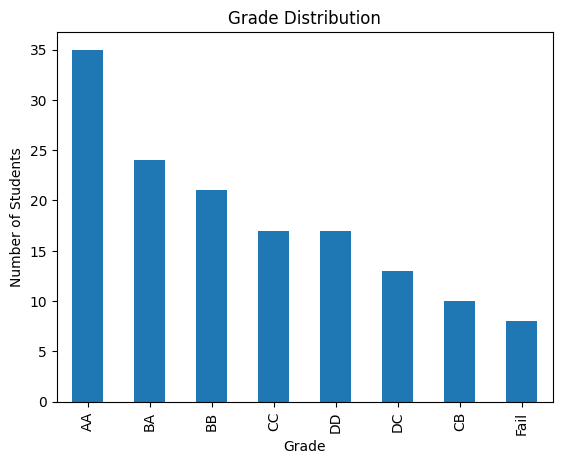

In [ ]:
import matplotlib.pyplot as plt

df["Grade"].value_counts().plot(kind="bar")
plt.title("Grade Distribution")
plt.xlabel("Grade")
plt.ylabel("Number of Students")
plt.show()

**Step 4 -- EDA**

*What factors appear to be associated with student grades?*

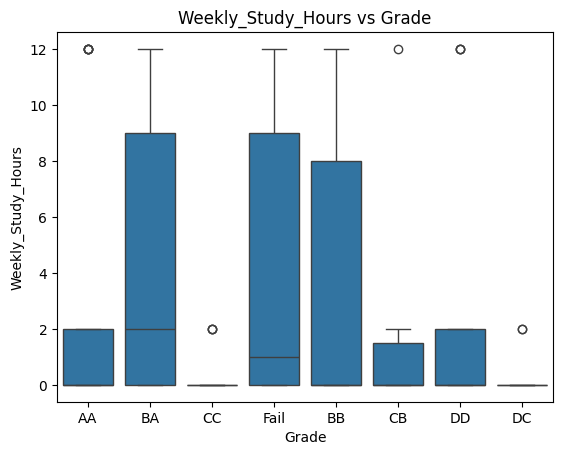

In [ ]:
# Question 1: Does study time relate to grade?

import seaborn as sns

sns.boxplot(x="Grade", y="Weekly_Study_Hours", data=df)
plt.title("Weekly_Study_Hours vs Grade")
plt.show()

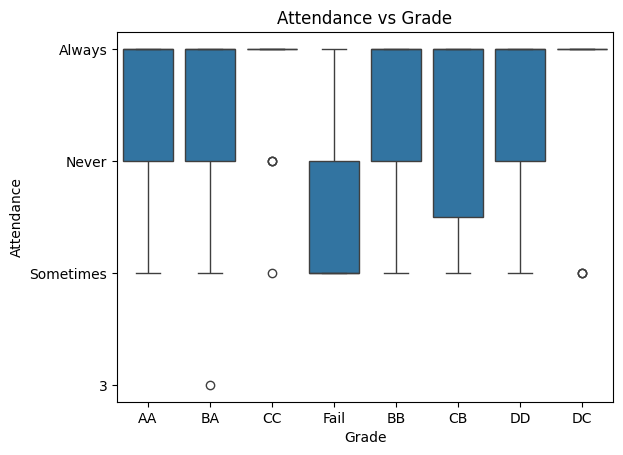

In [ ]:
# Question 2: Does attendance relate to grade?

sns.boxplot(x="Grade", y="Attendance", data=df)
plt.title("Attendance vs Grade")
plt.show()

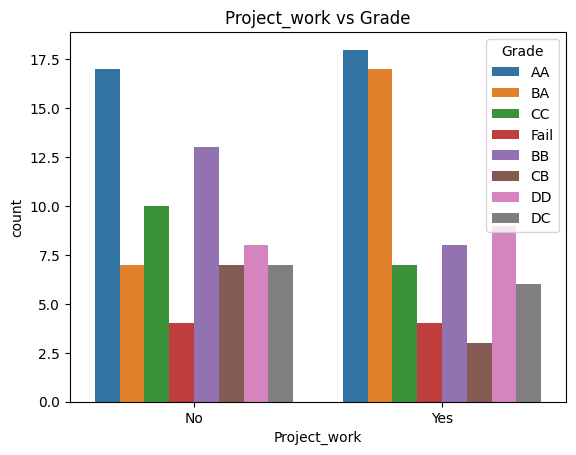

In [ ]:
# Question 3: Does project work matter?

sns.countplot(x="Project_work", hue="Grade", data=df)
plt.title("Project_work vs Grade")
plt.show()

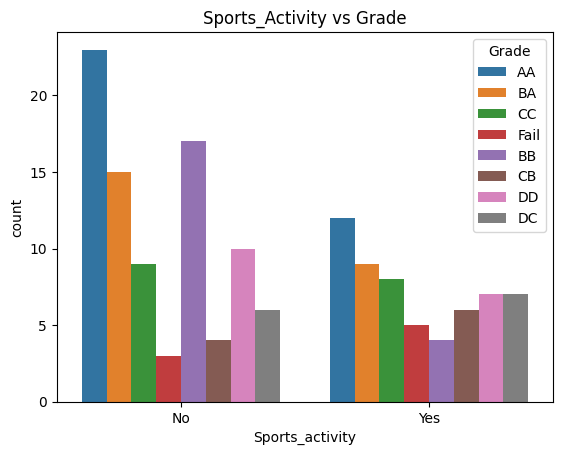

In [ ]:
# Question 4: Does sports participation relate to performance?

sns.countplot(x="Sports_activity", hue="Grade", data=df)
plt.title("Sports_Activity vs Grade")
plt.show()

**Numerical correlation analysis**

*helps to understand relationships between data.*

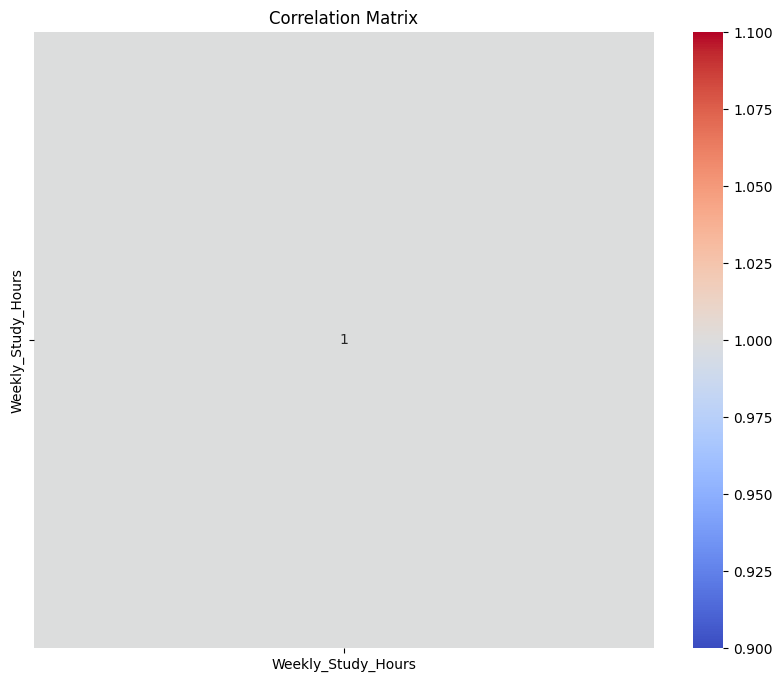

In [ ]:
numeric_df = df.select_dtypes(include="number")

plt.figure(figsize=(10, 8))
sns.heatmap(numeric_df.corr(), annot=True, cmap="coolwarm")
plt.title("Correlation Matrix")
plt.show()

**not use STUDENT ID as a predictive feature.**

*Because:*

Student ID = 101

Student ID = 102

Student ID = 103

In [ ]:
# Proper feature selction

df = df.drop(columns=["Student_ID"])

**Separate X and y**

In [ ]:
X = df.drop("Grade", axis=1)
y = df["Grade"]

In [ ]:
print(X.shape)
print(y.shape)

(145, 13)
(145,)


**Scikit-learn preprocessing pipelines**

In [ ]:
# First identifying columns :

categorical_features = X.select_dtypes(include="object").columns
numerical_features = X.select_dtypes(exclude="object").columns

print("Categorical:", categorical_features)
print("Numerical:", numerical_features)

Categorical: Index(['Student_Age', 'Sex', 'High_School_Type', 'Scholarship',
       'Additional_Work', 'Sports_activity', 'Transportation', 'Attendance',
       'Reading', 'Notes', 'Listening_in_Class', 'Project_work'],
      dtype='object')
Numerical: Index(['Weekly_Study_Hours'], dtype='object')


In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numerical_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
    ]
)

**Train-test split**

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

**Model 1 — Logistic Regression**

*Excellent baseline.*

In [ ]:
from sklearn.linear_model import LogisticRegression

**Model 2 — Decision Tree**

*Easy to explain visually.*

In [ ]:
from sklearn.tree import DecisionTreeClassifier

**Model 3 — Random Forest**

*Very useful for tabular data.*



In [ ]:
from sklearn.ensemble import RandomForestClassifier

**Model 4 -- Gradient Boosting**

*A strongest traditional ML model.*

In [ ]:
from sklearn.ensemble import GradientBoostingClassifier

**Pipeline**

In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier

rf_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestClassifier(
        n_estimators=200,
        random_state=42
    ))
])

rf_pipeline.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  Index(['Weekly_Study_Hours'], dtype='object')),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  Index(['Student_Age', 'Sex', 'High_School_Type', 'Scholarship',
       'Additional_Work', 'Sports_activity', 'Transportation', 'Attendance',
       'Reading', 'Notes', 'Listening_in_Class', 'Project_work'],
      dtype='object'))])),
                ('model',
                 RandomForestClassifier(n_estimators=200, random_state=42))])

In [ ]:
# Prediction

y_pred = rf_pipeline.predict(X_test)

**Evaluting the model properly**

In [ ]:
from sklearn.metrics import(
    accuracy_score,
    classification_report,
    confusion_matrix
)

print("Accuracy:", accuracy_score(y_test, y_pred))

print(classification_report(y_test, y_pred))

print(confusion_matrix(y_test, y_pred))

Accuracy: 0.2413793103448276
              precision    recall  f1-score   support

          AA       0.21      0.43      0.29         7
          BA       0.50      0.40      0.44         5
          BB       0.00      0.00      0.00         4
          CB       0.00      0.00      0.00         2
          CC       0.00      0.00      0.00         3
          DC       0.00      0.00      0.00         3
          DD       1.00      0.33      0.50         3
        Fail       0.50      0.50      0.50         2

    accuracy                           0.24        29
   macro avg       0.28      0.21      0.22        29
weighted avg       0.28      0.24      0.23        29

[[3 1 0 2 0 0 0 1]
 [2 2 1 0 0 0 0 0]
 [3 1 0 0 0 0 0 0]
 [2 0 0 0 0 0 0 0]
 [3 0 0 0 0 0 0 0]
 [0 0 1 0 2 0 0 0]
 [0 0 1 0 0 1 1 0]
 [1 0 0 0 0 0 0 1]]


**Confusion matrix**

*useful for presentation.*

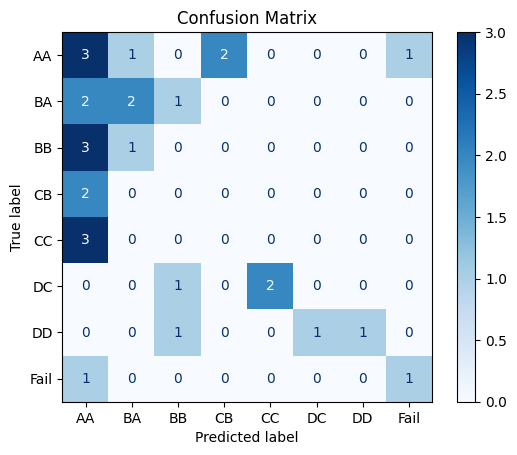

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    cmap="Blues"
)

plt.title("Confusion Matrix")
plt.show()

In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier

dt_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", DecisionTreeClassifier(
        n_estimators=200,
        random_state=42
    ))
])

dt_pipeline.fit(X_train, y_train)